# Lab 2 plots

## Setup

In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

folder = Path.cwd()  
data_folder = folder / "Final Data"
plot_folder = folder / "notebook_plots"
metric_folder = folder / "notebook_metrics"
plot_folder.mkdir(exist_ok=True)
metric_folder.mkdir(exist_ok=True)

blue = "#0066A1"  

def save_plot(fig, name):
    fig.savefig(plot_folder / (name + ".png"), dpi=plt.rcParams["savefig.dpi"])
    display(fig)
    plt.close(fig)


## Trials and gains

In [2]:
# Gain order: klp, klv, kap, kav, kli, kai.
trials = {
    "point_base": (
        "Point/P Controller Data/P_0.2_0.8 - Baseline",
        "P baseline", (0.2, 0, 0.8, 0, 0, 0),
    ),
    "point_p": (
        "Point/P Controller Data/P_0.6_0.75 - Good",
        "P tuned", (0.6, 0, 0.75, 0, 0, 0),
    ),
    "point_pid": (
        "Point/PID Controller Data/P_0.6_0.75 D_0.5_0.1 I_0.2_0.2 - Baseline and Good",
        "PID", (0.6, 0.5, 0.75, 0.1, 0.2, 0.2),
    ),
    "parabola_bad": (
        "Trajectory/Parabola/Parabola Data (PID) Bad (0.6, 0.5, 0.75, 0.1, 0.2, 0.2)",
        "PID initial", (0.6, 0.5, 0.75, 0.1, 0.2, 0.2),
    ),
    "parabola_pid": (
        "Trajectory/Parabola/Parabola Data Good (0.3, 0.2, 0.5, 0.1, 0.4, 0.3) (PID)",
        "PID final", (0.3, 0.2, 0.5, 0.1, 0.4, 0.3),
    ),
    "parabola_p": (
        "Trajectory/Parabola/Parabola Data (P) Good (0.3, 0.5)",
        "P final", (0.3, 0, 0.5, 0, 0, 0),
    ),
    "sigmoid_pid10": (
        "Trajectory/Sigmoid/Sigmoid Data bad waypoints (0.5, 0.15, 1.2, 0.3, 0.4, 0.3) (PID) (10 Waypoints)",
        "PID, 10 points", (0.5, 0.15, 1.2, 0.3, 0.4, 0.3),
    ),
    "sigmoid_pid20": (
        "Trajectory/Sigmoid/Sigmoid Data Good (0.5, 0.15, 1.2, 0.3, 0.4, 0.3) (PID) (20 Waypoints)",
        "PID, 20 points", (0.5, 0.15, 1.2, 0.3, 0.4, 0.3),
    ),
    "sigmoid_p10": (
        "Trajectory/Sigmoid/Sigmoid Data (P) Bad (0.5, 1.2)(10 Waypoints)",
        "P, 10 points", (0.5, 0, 1.2, 0, 0, 0),
    ),
    "sigmoid_p20": (
        "Trajectory/Sigmoid/Sigmoid (P) Good (0.5, 1.2)(20 Waypoints)",
        "P, 20 points", (0.5, 0, 1.2, 0, 0, 0),
    ),
}


## Read CSVs

In [3]:
def read_data(path):
    with open(path, newline="") as file:
        reader = csv.reader(file)
        next(reader)
        rows = [row for row in reader if row and row[0].strip()]

    values = []
    stamps = []
    for row in rows:
        values.append([float(row[0]), float(row[1]), float(row[2])])
        stamps.append(int(row[3]))
    values = np.array(values)
    stamps = np.array(stamps, dtype=np.int64)
    if not np.all(np.isfinite(values)) or np.any(np.diff(stamps) <= 0):
        raise ValueError(f"Nonfinite values or nonincreasing timestamps: {path}")
    return values, stamps

runs = {}
sensors = ["robot_pose", "linear", "angular"]

for key, (directory, label, gains) in trials.items():
    run = {"label": label, "gains": gains, "folder": directory}
    for sensor in sensors:
        path = data_folder / directory / (sensor + ".csv")
        values, stamps = read_data(path)
        run[sensor] = {"values": values, "stamps": stamps}

    # Use the same start time for all files in a trial.
    first_stamp = min(run[sensor]["stamps"][0] for sensor in sensors)
    for sensor in sensors:
        run[sensor]["time"] = (run[sensor]["stamps"] - first_stamp) / 1e9
    runs[key] = run

# robot_pose: x, y, theta.
# linear/angular: error, derivative, integral.
print(f"Loaded {len(runs)} trials.")


Loaded 10 trials.


## Figure 1: Point control

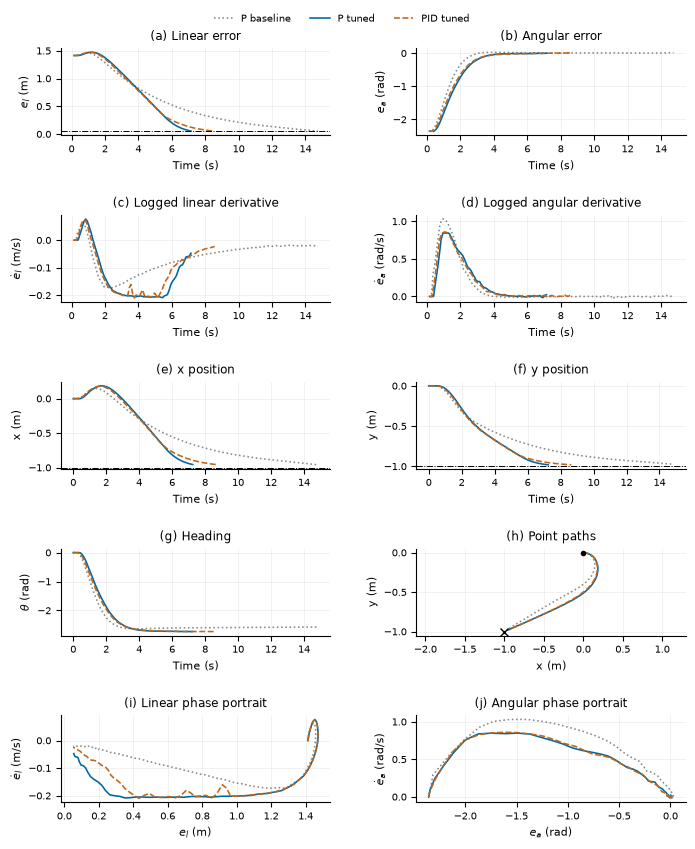

In [4]:
plt.rcdefaults()
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':8,
    'axes.titlesize':8.6, 'axes.labelsize':8, 'xtick.labelsize':7,
    'ytick.labelsize':7, 'legend.fontsize':7, 'axes.spines.top':False,
    'axes.spines.right':False, 'grid.alpha':.25, 'grid.linewidth':.5,
    'lines.linewidth':1.15, 'savefig.dpi':300, 'svg.fonttype':'none'})
fig, axes = plt.subplots(5,2,figsize=(7.1,8.35))
for key in ['point_base','point_p','point_pid']:
    r = runs[key]; c={'point_base':'#888888','point_p':blue,'point_pid':'#C06417'}[key]; ls={'point_base':':','point_p':'-','point_pid':'--'}[key]
    p=r['robot_pose']; l=r['linear']; a=r['angular']
    data = [(l['time'],l['values'][:,0]),(a['time'],a['values'][:,0]),
            (l['time'],l['values'][:,1]),(a['time'],a['values'][:,1]),
            (p['time'],p['values'][:,0]),(p['time'],p['values'][:,1]),
            (p['time'],p['values'][:,2]),(p['values'][:,0],p['values'][:,1]),
            (l['values'][:,0],l['values'][:,1]),(a['values'][:,0],a['values'][:,1])]
    for ax,(x,y) in zip(axes.flat,data):
        ax.plot(x,y,color=c,ls=ls,label={'point_base':'P baseline', 'point_p':'P tuned', 'point_pid':'PID tuned'}[key])
labels = [
    ('(a) Linear error','Time (s)',r'$e_l$ (m)'),
    ('(b) Angular error','Time (s)',r'$e_a$ (rad)'),
    ('(c) Logged linear derivative','Time (s)',r'$\dot e_l$ (m/s)'),
    ('(d) Logged angular derivative','Time (s)',r'$\dot e_a$ (rad/s)'),
    ('(e) x position','Time (s)','x (m)'),
    ('(f) y position','Time (s)','y (m)'),
    ('(g) Heading','Time (s)',r'$\theta$ (rad)'),
    ('(h) Point paths','x (m)','y (m)'),
    ('(i) Linear phase portrait',r'$e_l$ (m)',r'$\dot e_l$ (m/s)'),
    ('(j) Angular phase portrait',r'$e_a$ (rad)',r'$\dot e_a$ (rad/s)')]
for ax,(title,xlabel,ylabel) in zip(axes.flat,labels):
    ax.set(title=title,xlabel=xlabel,ylabel=ylabel)
    ax.grid(True)
for ax in [axes[2,0],axes[2,1]]:
    ax.axhline(-1,color='black',ls='-.',lw=.7)
axes[0,0].axhline(.05,color='black',ls='-.',lw=.7)
axes[3,1].plot(-1,-1,'kx',ms=6)
axes[3,1].plot(0,0,'ko',ms=3)
axes[3,1].set_aspect('equal',adjustable='datalim')
handles, labs = axes[0,0].get_legend_handles_labels()
fig.legend(handles,labs,loc='upper center',bbox_to_anchor=(.5,1.005),ncol=3,frameon=False)
fig.subplots_adjust(left=.105,right=.985,top=.953,bottom=.05,hspace=.92,wspace=.32)
save_plot(fig, 'point_responses')


## Extra tuning trials

In [5]:
# Extra trials from All Data/Point Data on GitHub.
tuning_specs = [
    ("P baseline", "P Controller Data/P_0.2_0.8 - Baseline", (0.2, 0.8), (0, 0), (0, 0)),
    ("P 0.6, 0.8", "P Controller Data/P_0.6_0.8", (0.6, 0.8), (0, 0), (0, 0)),
    ("P 0.6, 1.2", "P Controller Data/P_0.6_1.2", (0.6, 1.2), (0, 0), (0, 0)),
    ("P 0.6, 1.6", "P Controller Data/P_0.6_1.6", (0.6, 1.6), (0, 0), (0, 0)),
    ("P selected", "P Controller Data/P_0.6_0.75 - Good", (0.6, 0.75), (0, 0), (0, 0)),
    ("PD", "PD Controller Data/P_0.6_0.75 D_0.5_0.6 - Baseline", (0.6, 0.75), (0.5, 0.6), (0, 0)),
    ("PID", "PID Controller Data/P_0.6_0.75 D_0.5_0.1 I_0.2_0.2 - Baseline and Good", (0.6, 0.75), (0.5, 0.1), (0.2, 0.2)),
]

tuning_runs = {}
for label, directory, p_gains, d_gains, i_gains in tuning_specs:
    run = {"P": p_gains, "D": d_gains, "I": i_gains}
    for sensor in sensors:
        path = folder / "All Data" / "Point Data" / directory / (sensor + ".csv")
        values, stamps = read_data(path)
        run[sensor] = {"values": values, "stamps": stamps}
    first_stamp = min(run[sensor]["stamps"][0] for sensor in sensors)
    for sensor in sensors:
        run[sensor]["time"] = (run[sensor]["stamps"] - first_stamp) / 1e9
    tuning_runs[label] = run


## Figure 2: Point tuning

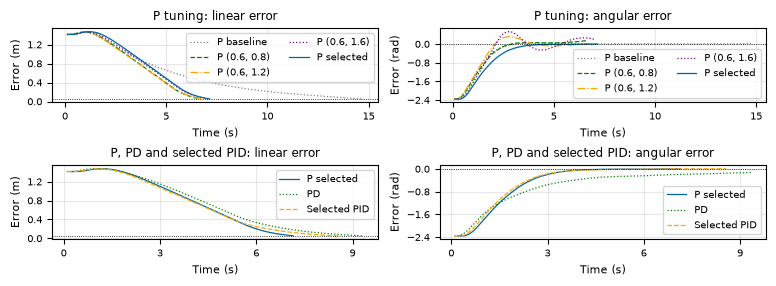

In [6]:
plt.rcdefaults()
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8,
    'axes.titlesize': 8.5, 'axes.labelsize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7, 'lines.linewidth': .9,
    'grid.alpha': .3, 'savefig.dpi': 400, 'svg.fonttype': 'none'})

fig, axes = plt.subplots(2, 2, figsize=(7.8, 2.9))
p_trials = [
    ("P baseline", "gray", ":"),
    ("P 0.6, 0.8", "green", "--"),
    ("P 0.6, 1.2", "orange", "-."),
    ("P 0.6, 1.6", "purple", ":"),
    ("P selected", blue, "-"),
]
controller_trials = [("P selected", blue, "-"), ("PD", "green", ":"), ("PID", "orange", "--")]
names = {"P 0.6, 0.8": "P (0.6, 0.8)", "P 0.6, 1.2": "P (0.6, 1.2)",
         "P 0.6, 1.6": "P (0.6, 1.6)", "PID": "Selected PID"}

for row, comparisons in enumerate([p_trials, controller_trials]):
    for name, colour, style in comparisons:
        run = tuning_runs[name]
        for column, sensor in enumerate(["linear", "angular"]):
            data = run[sensor]
            axes[row, column].plot(data["time"], data["values"][:, 0],
                color=colour, linestyle=style, label=names.get(name, name))
    for column, sensor in enumerate(["linear", "angular"]):
        ax = axes[row, column]
        title = "P tuning: " if row == 0 else "P, PD and selected PID: "
        ax.set(title=title + sensor + " error", xlabel="Time (s)",
               ylabel="Error (m)" if column == 0 else "Error (rad)")
        ax.axhline(0.05 if column == 0 else 0, color="black", linestyle=":", linewidth=.6)
        ax.grid(True)
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        ax.legend(loc="upper right" if column == 0 else "lower right",
                  ncol=2 if row == 0 else 1, fontsize=7)
fig.tight_layout(h_pad=.7, w_pad=1)
save_plot(fig, "point_tuning")


## Tuning results

In [7]:
tuning_results = []
for label, run in tuning_runs.items():
    pose = run["robot_pose"]["values"]
    time = run["robot_pose"]["time"]
    distance = np.sqrt((pose[:, 0] + 1) ** 2 + (pose[:, 1] + 1) ** 2)
    arrival = np.flatnonzero(distance < 0.05)[0]
    angular = run["angular"]["values"][:, 0]
    # These runs start with negative error, so positive error is overshoot.
    overshoot = np.degrees(max(0, angular.max()))
    tuning_results.append({
        "trial": label, "P": run["P"], "D": run["D"], "I": run["I"],
        "arrival_s": float(time[arrival]),
        "terminal_error_cm": float(100 * distance[-1]),
        "angular_overshoot_deg": float(overshoot),
    })

print("Trial            Arrival (s)   Final error (cm)   Angular overshoot (deg)")
for item in tuning_results:
    print(f'{item["trial"]:16} {item["arrival_s"]:8.2f}'
          f' {item["terminal_error_cm"]:17.3f} {item["angular_overshoot_deg"]:24.2f}')

with open(metric_folder / "point_tuning_metrics.csv", "w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(tuning_results[0]))
    writer.writeheader()
    writer.writerows(tuning_results)


Trial            Arrival (s)   Final error (cm)   Angular overshoot (deg)
P baseline          14.85             4.863                     1.72
P 0.6, 0.8           6.74             4.891                     8.72
P 0.6, 1.2           6.91             4.646                    17.93
P 0.6, 1.6           7.15             4.993                    30.34
P selected           7.25             4.916                     0.15
PD                   9.51             4.434                     0.00
PID                  8.65             4.904                     0.68


## Figure 3: Trajectories

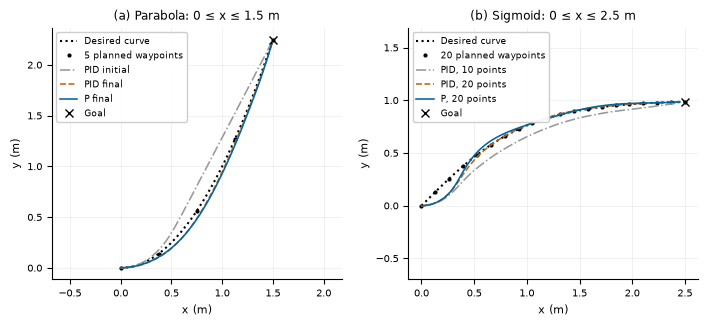

In [8]:
def planned_curve(kind, count):
    # Use the curves from planner.py.
    if kind == "parabola":
        x = np.linspace(0, 1.5, count)
        y = x ** 2
    else:
        x = np.linspace(0, 2.5, count)
        y = 2 / (1 + np.exp(-2 * x)) - 1
    return x, y

plt.rcdefaults()
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':8,
    'axes.titlesize':8.6, 'axes.labelsize':8, 'xtick.labelsize':7,
    'ytick.labelsize':7, 'legend.fontsize':7, 'axes.spines.top':False,
    'axes.spines.right':False, 'grid.alpha':.25, 'grid.linewidth':.5,
    'lines.linewidth':1.15, 'savefig.dpi':300, 'svg.fonttype':'none'})
fig, axes=plt.subplots(1,2,figsize=(7.1,3.35))
for ax,kind in zip(axes,['parabola','sigmoid']):
    xx=np.linspace(0,1.5 if kind=='parabola' else 2.5,1000)
    yy=xx**2 if kind=='parabola' else 2.0/(1.0+np.exp(-2.0*xx))-1.0
    ax.plot(xx,yy,'k:',lw=1.5,label='Desired curve')
    n=5 if kind=='parabola' else 20
    wx=np.linspace(xx[0],xx[-1],n)
    wy=wx**2 if kind=='parabola' else 2.0/(1.0+np.exp(-2.0*wx))-1.0
    ax.plot(wx,wy,'ko',ms=2,label=f'{n} planned waypoints')
    keys=['parabola_bad','parabola_pid','parabola_p'] if kind=='parabola' else ['sigmoid_pid10','sigmoid_pid20','sigmoid_p20']
    for k,c,ls in zip(keys,['#999999','#C06417','#0066A1'],['-.','--','-']):
        p=runs[k]['robot_pose']['values']
        ax.plot(p[:,0],p[:,1],color=c,ls=ls,label=runs[k]['label'])
    ax.plot(xx[-1],yy[-1],'kx',ms=6,label='Goal')
    ax.set(title='(a) Parabola: 0 ≤ x ≤ 1.5 m' if kind=='parabola' else '(b) Sigmoid: 0 ≤ x ≤ 2.5 m',xlabel='x (m)',ylabel='y (m)')
    ax.grid(True);ax.set_aspect('equal',adjustable='datalim')
    ax.legend(loc='upper left',fontsize=6.3,framealpha=.95)
fig.subplots_adjust(left=.08,right=.99,top=.91,bottom=.16,wspace=.23)
save_plot(fig, 'trajectory_comparison')


## Figure 4: Trajectory errors

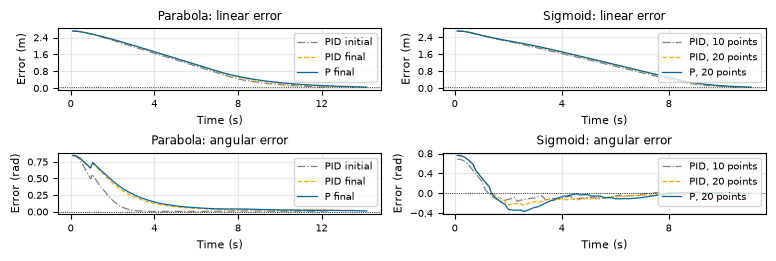

In [9]:
plt.rcdefaults()
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8,
    'axes.titlesize': 8.5, 'axes.labelsize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7, 'lines.linewidth': .9,
    'grid.alpha': .3, 'savefig.dpi': 400, 'svg.fonttype': 'none'})

fig, axes = plt.subplots(2, 2, figsize=(7.8, 2.65))
groups = [
    ("Parabola", ["parabola_bad", "parabola_pid", "parabola_p"]),
    ("Sigmoid", ["sigmoid_pid10", "sigmoid_pid20", "sigmoid_p20"]),
]
for column, (title, keys) in enumerate(groups):
    for key, colour, style in zip(keys, ["gray", "orange", blue], ["-.", "--", "-"]):
        run = runs[key]
        for row, sensor in enumerate(["linear", "angular"]):
            data = run[sensor]
            axes[row, column].plot(data["time"], data["values"][:, 0],
                color=colour, linestyle=style, label=run["label"])
    for row, sensor in enumerate(["linear", "angular"]):
        ax = axes[row, column]
        ax.set(title=title + ": " + sensor + " error", xlabel="Time (s)",
               ylabel="Error (m)" if row == 0 else "Error (rad)")
        ax.axhline(0.05 if row == 0 else 0, color="black", linestyle=":", linewidth=.6)
        ax.grid(True)
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        ax.legend(loc="upper right", fontsize=7)
fig.tight_layout(h_pad=.7, w_pad=1)
save_plot(fig, "trajectory_errors")


## Arrival time and final error

In [10]:
def area_under_curve(values, time):
    # Integrate using trapezoids.
    average = (values[1:] + values[:-1]) / 2
    return float(np.sum(average * np.diff(time)))

results = {}
for key, run in runs.items():
    pose = run["robot_pose"]["values"]
    time = run["robot_pose"]["time"]
    xy = pose[:, :2]
    if key.startswith("point"):
        goal = np.array([-1, -1])
    elif key.startswith("parabola"):
        goal = np.array([1.5, 2.25])
    else:
        goal = np.array([2.5, 2 / (1 + np.exp(-5)) - 1])

    distance = np.sqrt(np.sum((xy - goal) ** 2, axis=1))
    inside = np.flatnonzero(distance < 0.05)
    results[key] = {
        "label": run["label"],
        "gains_klp_klv_kap_kav_kli_kai": run["gains"],
        "duration_s": float(time[-1]),
        "final_x_m": float(xy[-1, 0]),
        "final_y_m": float(xy[-1, 1]),
        "terminal_radial_error_m": float(distance[-1]),
        "first_5cm_sample_s": float(time[inside[0]]),
    }
    run["goal"] = goal
    run["distance"] = distance

# Arrival is the first sample within 5 cm of the goal.
print("Controller       Arrival (s)   Final error (cm)")
for key in ["point_base", "point_p", "point_pid"]:
    item = results[key]
    print(f'{item["label"]:16} {item["first_5cm_sample_s"]:8.2f}'
          f' {100 * item["terminal_radial_error_m"]:17.3f}')


Controller       Arrival (s)   Final error (cm)
P baseline          14.85             4.863
P tuned              7.25             4.916
PID                  8.65             4.904


## Response and overshoot

In [11]:
def crossing_time(time, values, threshold):
    indices = np.flatnonzero(values <= threshold)
    if len(indices) == 0:
        return None
    index = indices[0]
    if index == 0:
        return float(time[0])
    # Estimate the crossing time between samples.
    fraction = (threshold - values[index - 1]) / (values[index] - values[index - 1])
    return float(time[index - 1] + fraction * (time[index] - time[index - 1]))

for key in ["point_base", "point_p", "point_pid"]:
    run = runs[key]
    xy = run["robot_pose"]["values"][:, :2]
    time = run["robot_pose"]["time"]
    distance = run["distance"]

    t10 = crossing_time(time, distance, 0.9 * distance[0])
    t90 = crossing_time(time, distance, 0.1 * distance[0])

    direction = run["goal"] - xy[0]
    travelled = xy - xy[0]
    # Progress above 1 means the robot passed the goal along this direction.
    progress = np.sum(travelled * direction, axis=1) / np.sum(direction ** 2)
    angular_error = run["angular"]["values"][:, 0]

    results[key].update({
        "radial_10_90_rise_s": t90 - t10,
        "radial_t10_s": t10,
        "radial_t90_s": t90,
        "goal_line_overshoot_pct": float(max(0, 100 * (progress.max() - 1))),
        "peak_positive_angular_error_rad": float(max(0, angular_error.max())),
    })

print("Controller       Goal overshoot (%)   Angular overshoot (deg)")
for key in ["point_base", "point_p", "point_pid"]:
    item = results[key]
    angle = np.degrees(item["peak_positive_angular_error_rad"])
    print(f'{item["label"]:16} {item["goal_line_overshoot_pct"]:12.2f} {angle:24.2f}')


Controller       Goal overshoot (%)   Angular overshoot (deg)
P baseline               0.00                     1.72
P tuned                  0.00                     0.15
PID                      0.00                     0.68


## Distance from the curve

In [12]:
def curve_distances(xy, kind):
    # Approximate the curve with 5000 line segments.
    x, y = planned_curve(kind, 5001)
    starts = np.column_stack((x[:-1], y[:-1]))
    segments = np.column_stack((np.diff(x), np.diff(y)))
    lengths_squared = np.sum(segments ** 2, axis=1)

    distances = []
    for position in xy:
        # Find the closest point on the curve.
        offset = position - starts
        fraction = np.sum(offset * segments, axis=1) / lengths_squared
        fraction = np.clip(fraction, 0, 1)
        closest = starts + fraction[:, None] * segments
        distance_squared = np.sum((position - closest) ** 2, axis=1)
        distances.append(np.sqrt(distance_squared.min()))
    return np.array(distances)

for key, run in runs.items():
    if key.startswith("point"):
        continue
    kind = "parabola" if key.startswith("parabola") else "sigmoid"
    pose = run["robot_pose"]["values"]
    time = run["robot_pose"]["time"]
    distance = curve_distances(pose[:, :2], kind)

    results[key]["curve_max_distance_m"] = float(distance.max())
    results[key]["curve_rms_distance_m"] = float(
        np.sqrt(area_under_curve(distance ** 2, time) / time[-1])
    )

print("Trial               Peak deviation (cm)   RMS deviation (cm)")
for key, item in results.items():
    if "curve_max_distance_m" in item:
        print(f'{key:20} {100 * item["curve_max_distance_m"]:16.2f}'
              f' {100 * item["curve_rms_distance_m"]:20.2f}')


Trial               Peak deviation (cm)   RMS deviation (cm)
parabola_bad                    13.28                 7.67
parabola_pid                     4.55                 2.15
parabola_p                       4.68                 2.34
sigmoid_pid10                   11.54                 7.43
sigmoid_pid20                   10.06                 3.29
sigmoid_p10                     11.19                 6.23
sigmoid_p20                     10.03                 3.25


## Save results

In [13]:

fields = []
for item in results.values():
    for field in item:
        if field not in fields:
            fields.append(field)

with open(metric_folder / "metrics.csv", "w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=["run"] + fields)
    writer.writeheader()
    for key, item in results.items():
        writer.writerow({"run": key, **item})

print("Figures saved in notebook_plots.")
print("Metrics saved in notebook_metrics.")


Figures saved in notebook_plots.
Metrics saved in notebook_metrics.


## Comparison table

In [14]:
def settling_time(time, error, band):
    # Settling: the last crossing into the tolerance before logging ends.
    outside = np.flatnonzero(np.abs(error) > band)
    if len(outside) == 0:
        return float(time[0])
    last = outside[-1]
    if last == len(error) - 1:
        return None
    before, after = abs(error[last]), abs(error[last + 1])
    fraction = (band - before) / (after - before)
    return float(time[last] + fraction * (time[last + 1] - time[last]))

table_results = []
for key, name in [("point_base", "Baseline P"), ("point_p", "Selected P"), ("point_pid", "Selected PID")]:
    run = runs[key]
    pose = run["robot_pose"]["values"]
    time = run["robot_pose"]["time"]
    distance = np.sqrt((pose[:, 0] + 1) ** 2 + (pose[:, 1] + 1) ** 2)
    angular = run["angular"]["values"][:, 0]
    angular_time = run["angular"]["time"]
    magnitude = np.abs(angular)
    linear_response = crossing_time(time, distance, .1 * distance[0]) - crossing_time(time, distance, .9 * distance[0])
    angular_response = crossing_time(angular_time, magnitude, .1 * magnitude[0]) - crossing_time(angular_time, magnitude, .9 * magnitude[0])
    angular_peak = max(0, float(angular.max()))
    arrival = np.flatnonzero(distance < .05)[0]
    direction = np.array([-1., -1.]) - pose[0, :2]
    progress = (pose[:, :2] - pose[0, :2]) @ direction / (direction @ direction)
    table_results.append({
        "controller": name,
        "linear_response_s": linear_response,
        "angular_response_s": angular_response,
        "linear_settling_5pct_s": settling_time(time, distance, .05 * distance[0]),
        "angular_settling_5pct_s": settling_time(angular_time, angular, .05 * magnitude[0]),
        "arrival_5cm_s": float(time[arrival]),
        "final_position_error_cm": float(distance[-1] * 100),
        "final_angular_error_deg": float(np.degrees(angular[-1])),
        "position_overshoot_pct": max(0, float(progress.max() - 1)) * 100,
        "angular_overshoot_deg": float(np.degrees(angular_peak)),
        "angular_overshoot_pct": angular_peak / magnitude[0] * 100,
    })

with open(metric_folder / "point_comparison.csv", "w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(table_results[0]))
    writer.writeheader()
    writer.writerows(table_results)
for row in table_results:
    print(row["controller"])
    for name, value in row.items():
        if name != "controller":
            print(f"  {name}: {value:.3f}")


Baseline P
  linear_response_s: 9.763
  angular_response_s: 1.622
  linear_settling_5pct_s: 14.124
  angular_settling_5pct_s: 2.478
  arrival_5cm_s: 14.851
  final_position_error_cm: 4.863
  final_angular_error_deg: 1.065
  position_overshoot_pct: 0.000
  angular_overshoot_deg: 1.719
  angular_overshoot_pct: 1.274
Selected P
  linear_response_s: 3.918
  angular_response_s: 2.122
  linear_settling_5pct_s: 6.933
  angular_settling_5pct_s: 3.326
  arrival_5cm_s: 7.248
  final_position_error_cm: 4.916
  final_angular_error_deg: 0.153
  position_overshoot_pct: 0.000
  angular_overshoot_deg: 0.153
  angular_overshoot_pct: 0.114
Selected PID
  linear_response_s: 4.632
  angular_response_s: 2.118
  linear_settling_5pct_s: 8.064
  angular_settling_5pct_s: 3.254
  arrival_5cm_s: 8.655
  final_position_error_cm: 4.904
  final_angular_error_deg: 0.680
  position_overshoot_pct: 0.000
  angular_overshoot_deg: 0.680
  angular_overshoot_pct: 0.504


## Intermediate PID

P = (0.6, 0.75), D = (0.5, 0.6), I = (0.2, 0.2).

In [15]:
directory = data_folder / "Point/PID Controller Data/P_0.6_0.75 D_0.5_0.6 I_0.2_0.2 - Intermediate"
intermediate = {}
for sensor in sensors:
    path = directory / (sensor + ".csv")
    values, stamps = read_data(path)
    intermediate[sensor] = {"values": values, "stamps": stamps}

first_stamp = min(intermediate[sensor]["stamps"][0] for sensor in sensors)
pose = intermediate["robot_pose"]["values"]
time = (intermediate["robot_pose"]["stamps"] - first_stamp) / 1e9
angular = intermediate["angular"]["values"][:, 0]

distance = np.sqrt((pose[:, 0] + 1) ** 2 + (pose[:, 1] + 1) ** 2)
arrival = np.flatnonzero(distance < 0.05)[0]
intermediate_metrics = {
    "arrival_s": float(time[arrival]),
    "angular_overshoot_deg": float(np.degrees(max(0, angular.max()))),
    "final_heading_error_deg": float(np.degrees(angular[-1])),
}

for name, value in intermediate_metrics.items():
    print(f"{name}: {value:.2f}")
with open(metric_folder / "intermediate_pid_metrics.csv", "w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=list(intermediate_metrics))
    writer.writeheader()
    writer.writerow(intermediate_metrics)


arrival_s: 9.20
angular_overshoot_deg: 0.41
final_heading_error_deg: -0.13


## Other report numbers

In [16]:
report_numbers = []

def report_number(name, value, unit):
    report_numbers.append({"quantity": name, "value": float(value), "unit": unit})
    print(f"{name}: {value:.3f} {unit}")

for key in ["point_base", "point_p", "point_pid"]:
    initial_distance = runs[key]["distance"][0]
    initial_angle = np.degrees(runs[key]["angular"]["values"][0, 0])
    report_number(key + " initial distance", initial_distance, "m")
    report_number(key + " initial heading error", initial_angle, "deg")
    report_number(key + " 5% distance band", 0.05 * initial_distance * 100, "cm")
    report_number(key + " 5% heading band", 0.05 * abs(initial_angle), "deg")

pd_angle = tuning_runs["PD"]["angular"]["values"][-1, 0]
report_number("PD final heading error", np.degrees(pd_angle), "deg")

baseline_time = results["point_base"]["first_5cm_sample_s"]
p_time = results["point_p"]["first_5cm_sample_s"]
pid_time = results["point_pid"]["first_5cm_sample_s"]
p08_time = next(row["arrival_s"] for row in tuning_results if row["trial"] == "P 0.6, 0.8")
report_number("Selected P extra time over P (0.6, 0.8)", p_time - p08_time, "s")
report_number("Selected P time saved versus PID", pid_time - p_time, "s")
report_number("Selected P time saved versus PID", 100 * (pid_time - p_time) / pid_time, "%")
report_number("Selected P time saved versus baseline", 100 * (baseline_time - p_time) / baseline_time, "%")

for key in ["parabola_bad", "parabola_pid", "parabola_p", "sigmoid_pid10", "sigmoid_pid20", "sigmoid_p20"]:
    report_number(key + " arrival", results[key]["first_5cm_sample_s"], "s")
    report_number(key + " maximum curve distance", 100 * results[key]["curve_max_distance_m"], "cm")
    report_number(key + " RMS curve distance", 100 * results[key]["curve_rms_distance_m"], "cm")
extra_time = results["parabola_pid"]["first_5cm_sample_s"] - results["parabola_bad"]["first_5cm_sample_s"]
report_number("Parabola PID extra time after tuning", extra_time, "s")

with open(metric_folder / "report_extra_metrics.csv", "w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=["quantity", "value", "unit"])
    writer.writeheader()
    writer.writerows(report_numbers)

point_base initial distance: 1.414 m
point_base initial heading error: -135.000 deg
point_base 5% distance band: 7.071 cm
point_base 5% heading band: 6.750 deg
point_p initial distance: 1.414 m
point_p initial heading error: -135.000 deg
point_p 5% distance band: 7.071 cm
point_p 5% heading band: 6.750 deg
point_pid initial distance: 1.414 m
point_pid initial heading error: -135.000 deg
point_pid 5% distance band: 7.071 cm
point_pid 5% heading band: 6.750 deg
PD final heading error: -7.266 deg
Selected P extra time over P (0.6, 0.8): 0.509 s
Selected P time saved versus PID: 1.406 s
Selected P time saved versus PID: 16.251 %
Selected P time saved versus baseline: 51.192 %
parabola_bad arrival: 12.452 s
parabola_bad maximum curve distance: 13.283 cm
parabola_bad RMS curve distance: 7.670 cm
parabola_pid arrival: 13.652 s
parabola_pid maximum curve distance: 4.545 cm
parabola_pid RMS curve distance: 2.146 cm
parabola_p arrival: 14.260 s
parabola_p maximum curve distance: 4.680 cm
parabol